<a href="https://colab.research.google.com/github/oabdelhalim8/ML---7/blob/main/ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys

assert sys.version_info >= (3, 10)

In [2]:
from packaging.version import Version
import sklearn

assert Version(sklearn.__version__) >= Version("1.6.1")

In [3]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

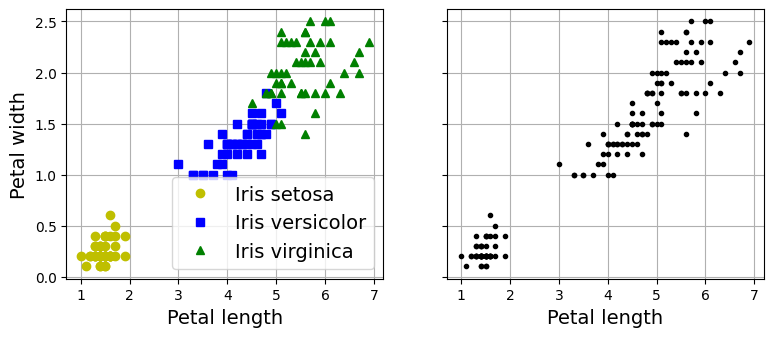

In [4]:
# extra code – this cell generates Figure 8–1

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

data = load_iris()
X = data.data
y = data.target
data.target_names

plt.figure(figsize=(9, 3.5))

plt.subplot(121)
plt.plot(X[y==0, 2], X[y==0, 3], "yo", label="Iris setosa")
plt.plot(X[y==1, 2], X[y==1, 3], "bs", label="Iris versicolor")
plt.plot(X[y==2, 2], X[y==2, 3], "g^", label="Iris virginica")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.grid()
plt.legend()

plt.subplot(122)
plt.scatter(X[:, 2], X[:, 3], c="k", marker=".")
plt.xlabel("Petal length")
plt.tick_params(labelleft=False)
plt.gca().set_axisbelow(True)
plt.grid()

plt.show()

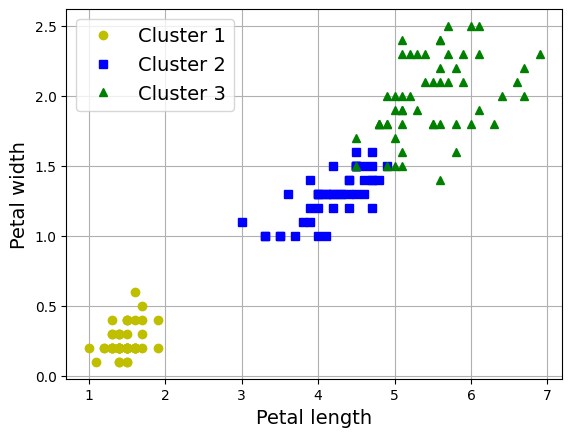

In [5]:
# extra code

import numpy as np
from scipy import stats
from sklearn.mixture import GaussianMixture

y_pred = GaussianMixture(n_components=3, random_state=42).fit(X).predict(X)

mapping = {}
for class_id in np.unique(y):
    mode, _ = stats.mode(y_pred[y==class_id])
    mapping[mode] = class_id

y_pred = np.array([mapping[cluster_id] for cluster_id in y_pred])

plt.plot(X[y_pred==0, 2], X[y_pred==0, 3], "yo", label="Cluster 1")
plt.plot(X[y_pred==1, 2], X[y_pred==1, 3], "bs", label="Cluster 2")
plt.plot(X[y_pred==2, 2], X[y_pred==2, 3], "g^", label="Cluster 3")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="upper left")
plt.grid()
plt.show()

In [6]:
(y_pred==y).sum() / len(y_pred)

np.float64(0.9666666666666667)

In [7]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# extra code – the exact arguments of make_blobs() are not important
blob_centers = np.array([[ 0.2,  2.3], [-1.5 ,  2.3], [-2.8,  1.8],
                         [-2.8,  2.8], [-2.8,  1.3]])
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])
X, y = make_blobs(n_samples=2000, centers=blob_centers, cluster_std=blob_std,
                  random_state=7)

k = 5
kmeans = KMeans(n_clusters=k, random_state=43)
y_pred = kmeans.fit_predict(X)

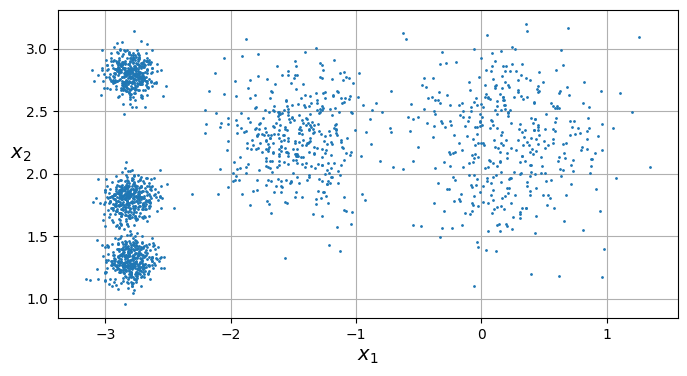

In [8]:
# extra code – this cell generates Figure 8–2

def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$", rotation=0)

plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.gca().set_axisbelow(True)
plt.grid()

plt.show()

In [9]:
y_pred

array([4, 0, 1, ..., 2, 1, 0], shape=(2000,), dtype=int32)

In [10]:
y_pred is kmeans.labels_

True

In [11]:
kmeans.cluster_centers_

array([[-2.80389616,  1.80117999],
       [ 0.20876306,  2.25551336],
       [-2.79290307,  2.79641063],
       [-1.46679593,  2.28585348],
       [-2.80037642,  1.30082566]])

In [12]:
kmeans.labels_

array([4, 0, 1, ..., 2, 1, 0], shape=(2000,), dtype=int32)

In [13]:
import numpy as np

X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(X_new)

array([1, 1, 2, 2], dtype=int32)

In [14]:
kmeans.transform(X_new).round(2)

array([[2.81, 0.33, 2.9 , 1.49, 2.89],
       [5.81, 2.8 , 5.85, 4.48, 5.84],
       [1.21, 3.29, 0.29, 1.69, 1.71],
       [0.73, 3.22, 0.36, 1.55, 1.22]])

In [15]:
# extra code
np.linalg.norm(np.tile(X_new, (1, k)).reshape(-1, k, 2)
               - kmeans.cluster_centers_, axis=2).round(2)

array([[2.81, 0.33, 2.9 , 1.49, 2.89],
       [5.81, 2.8 , 5.85, 4.48, 5.84],
       [1.21, 3.29, 0.29, 1.69, 1.71],
       [0.73, 3.22, 0.36, 1.55, 1.22]])

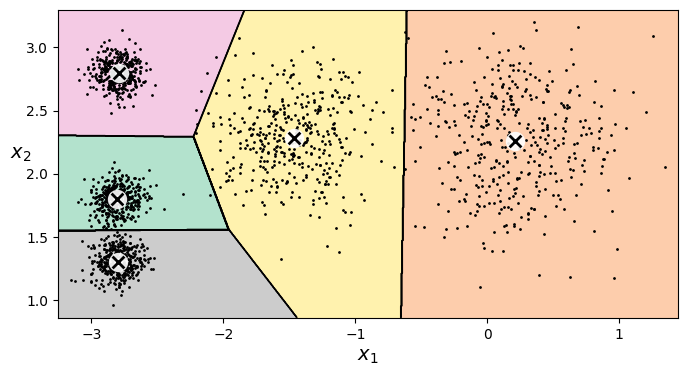

In [16]:
# extra code – this cell generates Figure 8–3

def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=35, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=12,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)

plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)

plt.show()

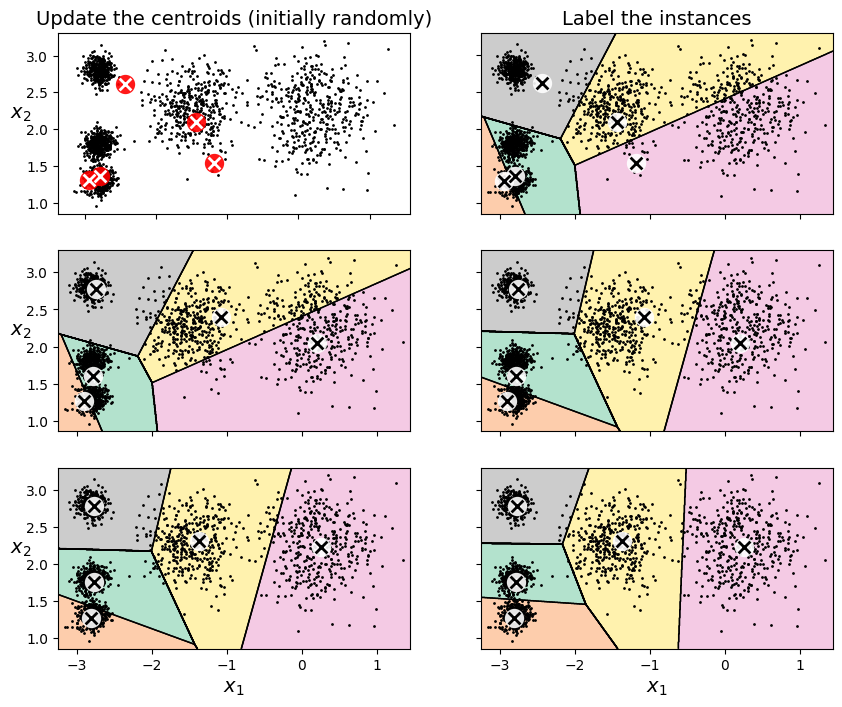

In [17]:
# extra code – this cell generates Figure 8–4

kmeans_iter1 = KMeans(n_clusters=5, init="random", n_init=1, max_iter=1,
                      random_state=18)
kmeans_iter2 = KMeans(n_clusters=5, init="random", n_init=1, max_iter=2,
                      random_state=18)
kmeans_iter3 = KMeans(n_clusters=5, init="random", n_init=1, max_iter=3,
                      random_state=18)
kmeans_iter1.fit(X)
kmeans_iter2.fit(X)
kmeans_iter3.fit(X)

plt.figure(figsize=(10, 8))

plt.subplot(321)
plot_data(X)
plot_centroids(kmeans_iter1.cluster_centers_, circle_color='r', cross_color='w')
plt.ylabel("$x_2$", rotation=0)
plt.tick_params(labelbottom=False)
plt.title("Update the centroids (initially randomly)")

plt.subplot(322)
plot_decision_boundaries(kmeans_iter1, X, show_xlabels=False,
                         show_ylabels=False)
plt.title("Label the instances")

plt.subplot(323)
plot_decision_boundaries(kmeans_iter1, X, show_centroids=False,
                         show_xlabels=False)
plot_centroids(kmeans_iter2.cluster_centers_)

plt.subplot(324)
plot_decision_boundaries(kmeans_iter2, X, show_xlabels=False,
                         show_ylabels=False)

plt.subplot(325)
plot_decision_boundaries(kmeans_iter2, X, show_centroids=False)
plot_centroids(kmeans_iter3.cluster_centers_)

plt.subplot(326)
plot_decision_boundaries(kmeans_iter3, X, show_ylabels=False)


plt.show()

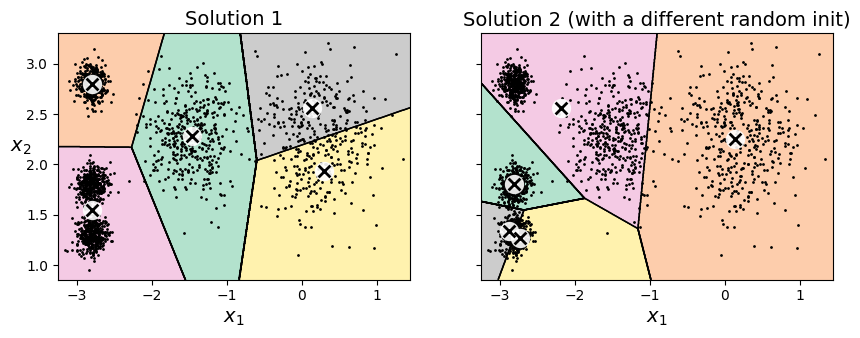

In [18]:
# extra code – this cell generates Figure 8–5

def plot_clusterer_comparison(clusterer1, clusterer2, X, title1=None,
                              title2=None):
    clusterer1.fit(X)
    clusterer2.fit(X)

    plt.figure(figsize=(10, 3.2))

    plt.subplot(121)
    plot_decision_boundaries(clusterer1, X)
    if title1:
        plt.title(title1)

    plt.subplot(122)
    plot_decision_boundaries(clusterer2, X, show_ylabels=False)
    if title2:
        plt.title(title2)

kmeans_rnd_init1 = KMeans(n_clusters=5, init="random", n_init=1, random_state=2)
kmeans_rnd_init2 = KMeans(n_clusters=5, init="random", n_init=1, random_state=8)

plot_clusterer_comparison(kmeans_rnd_init1, kmeans_rnd_init2, X,
                          "Solution 1",
                          "Solution 2 (with a different random init)")


plt.show()

In [19]:
good_init = np.array([[-3, 3], [-3, 2], [-3, 1], [-1, 2], [0, 2]])
kmeans = KMeans(n_clusters=5, init=good_init, random_state=42)
kmeans.fit(X)

KMeans(init=array([[-3,  3],
       [-3,  2],
       [-3,  1],
       [-1,  2],
       [ 0,  2]]),
       n_clusters=5, random_state=42)

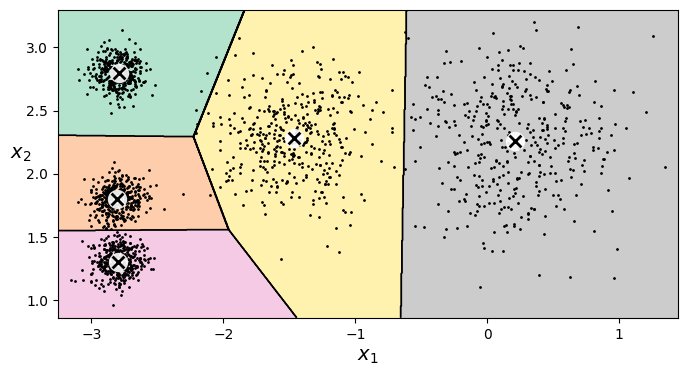

In [20]:
# extra code
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)

In [21]:
kmeans.inertia_

211.59853725816828

In [22]:
kmeans_rnd_init1.inertia_  # extra code

219.58201503602285

In [23]:
kmeans_rnd_init2.inertia_  # extra code

600.3600713094229

In [24]:
# extra code
X_dist = kmeans.transform(X)
(X_dist[np.arange(len(X_dist)), kmeans.labels_] ** 2).sum()

np.float64(211.59853725816882)

In [25]:
kmeans.score(X)

-211.59853725816828

In [26]:
# extra code
kmeans_rnd_10_inits = KMeans(n_clusters=5, init="random", n_init=10,
                             random_state=2)
kmeans_rnd_10_inits.fit(X)

KMeans(init='random', n_clusters=5, n_init=10, random_state=2)

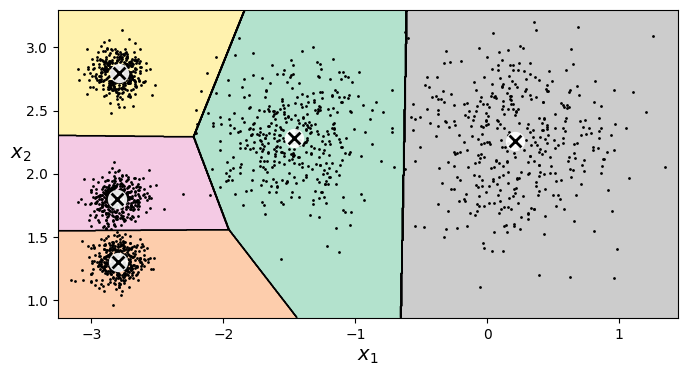

In [27]:
# extra code
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans_rnd_10_inits, X)
plt.show()

In [28]:
kmeans_rnd_10_inits.inertia_

211.59853725816828

In [29]:
from sklearn.cluster import MiniBatchKMeans

minibatch_kmeans = MiniBatchKMeans(n_clusters=5, random_state=42)
minibatch_kmeans.fit(X)

MiniBatchKMeans(n_clusters=5, random_state=42)

In [30]:
minibatch_kmeans.inertia_

211.65945105712612

In [31]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)

In [32]:
X_train, y_train = mnist.data[:60000], mnist.target[:60000]
X_test, y_test = mnist.data[60000:], mnist.target[60000:]

In [33]:
filename = "my_mnist.mmap"
X_memmap = np.memmap(filename, dtype='float32', mode='write',
                     shape=X_train.shape)
X_memmap[:] = X_train
X_memmap.flush()

In [34]:
from sklearn.cluster import MiniBatchKMeans

minibatch_kmeans = MiniBatchKMeans(n_clusters=10, batch_size=10,
                                   random_state=42)
minibatch_kmeans.fit(X_memmap)

MiniBatchKMeans(batch_size=10, n_clusters=10, random_state=42)

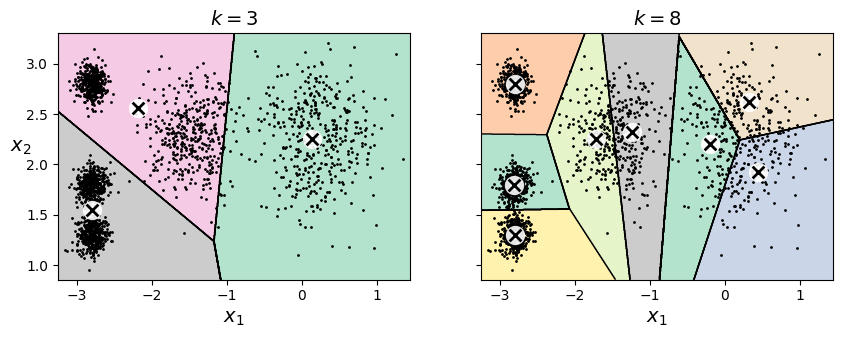

In [35]:
# extra code – this cell generates Figure 8–6

kmeans_k3 = KMeans(n_clusters=3, random_state=42)
kmeans_k8 = KMeans(n_clusters=8, random_state=42)

plot_clusterer_comparison(kmeans_k3, kmeans_k8, X, "$k=3$", "$k=8$")

plt.show()

In [36]:
kmeans_k3.inertia_

653.2167190021554

In [37]:
kmeans_k8.inertia_

127.13141880461835

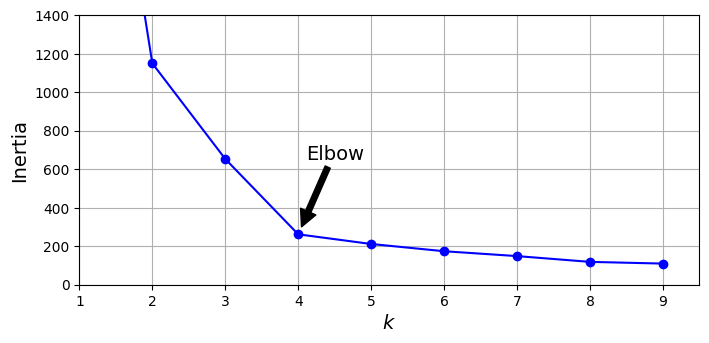

In [38]:
# extra code – this cell generates Figure 8–7

kmeans_per_k = [KMeans(n_clusters=k, random_state=43).fit(X)
                for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.annotate("", xy=(4, inertias[3]), xytext=(4.45, 650),
             arrowprops=dict(facecolor='black', shrink=0.1))
plt.text(4.5, 650, "Elbow", horizontalalignment="center")
plt.axis([1, 9.5, 0, 1400])
plt.grid()

plt.show()

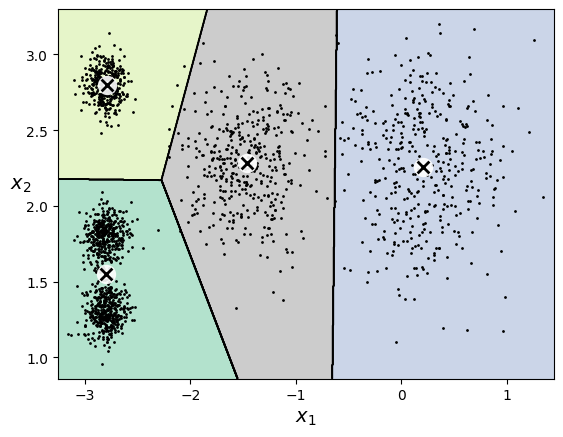

In [39]:
# extra code
plot_decision_boundaries(kmeans_per_k[4 - 1], X)
plt.show()

In [40]:
from sklearn.metrics import silhouette_score

In [41]:
silhouette_score(X, kmeans.labels_)

np.float64(0.655517642572828)

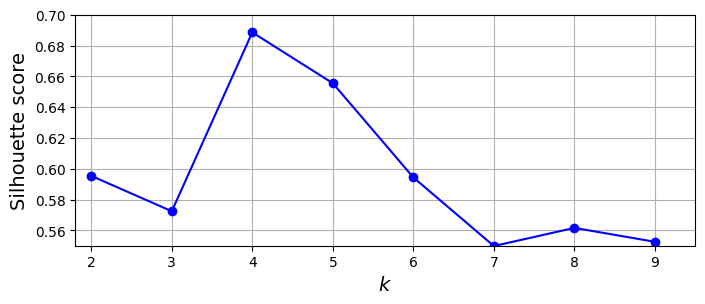

In [42]:
# extra code – this cell generates Figure 8–8

silhouette_scores = [silhouette_score(X, model.labels_)
                     for model in kmeans_per_k[1:]]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.axis([1.8, 9.5, 0.55, 0.7])
plt.grid()

plt.show()

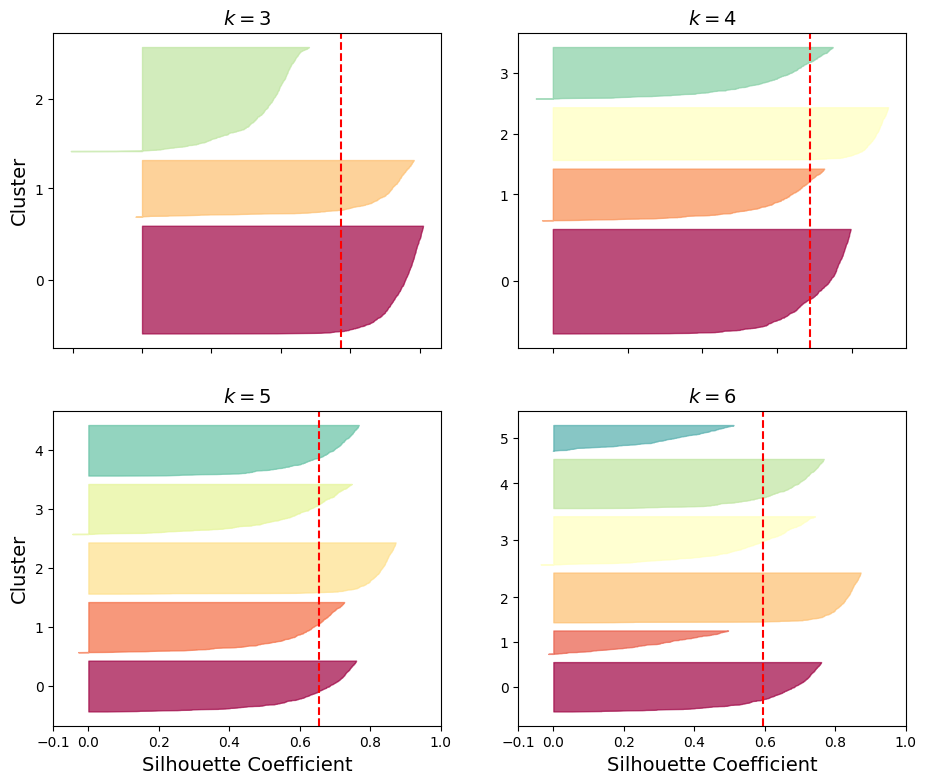

In [43]:
# extra code – this cell generates Figure 8–9

from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter

plt.figure(figsize=(11, 9))

for k in (3, 4, 5, 6):
    plt.subplot(2, 2, k - 2)

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = plt.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (3, 5):
        plt.ylabel("Cluster")

    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title(f"$k={k}$")


plt.show()

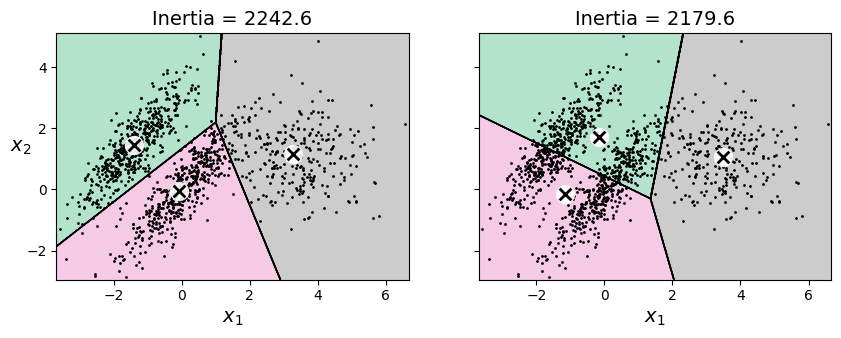

In [44]:
# extra code – this cell generates Figure 8–10

X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
X = np.r_[X1, X2]
y = np.r_[y1, y2]

kmeans_good = KMeans(n_clusters=3,
                     init=np.array([[-1.5, 2.5], [0.5, 0], [4, 0]]),
                     random_state=42)
kmeans_bad = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_good.fit(X)
kmeans_bad.fit(X)

plt.figure(figsize=(10, 3.2))

plt.subplot(121)
plot_decision_boundaries(kmeans_good, X)
plt.title(f"Inertia = {kmeans_good.inertia_:.1f}")

plt.subplot(122)
plot_decision_boundaries(kmeans_bad, X, show_ylabels=False)
plt.title(f"Inertia = {kmeans_bad.inertia_:.1f}")


plt.show()

In [45]:
from pathlib import Path

filepath = Path("/content/meee.png")

if filepath.is_file():
    print("Image found:", filepath)
else:
    print("Image not found. Check the file path.")

Image found: /content/meee.png


In [46]:
import PIL

image = np.asarray(PIL.Image.open(filepath))
image.shape

(1024, 768, 3)

In [47]:
X = image.reshape(-1, 3)
kmeans = KMeans(n_clusters=8, random_state=42).fit(X)
segmented_img = kmeans.cluster_centers_[kmeans.labels_]
segmented_img = segmented_img.reshape(image.shape)

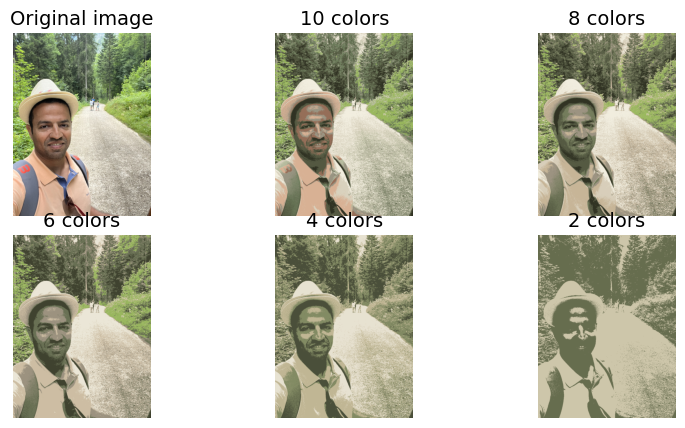

In [48]:
# extra code – this cell generates Figure 8–11

segmented_imgs = []
n_colors = (10, 8, 6, 4, 2)
for n_clusters in n_colors:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42).fit(X)
    segmented_img = kmeans.cluster_centers_[kmeans.labels_]
    segmented_imgs.append(segmented_img.reshape(image.shape))

plt.figure(figsize=(10, 5))
plt.subplots_adjust(wspace=0.05, hspace=0.1)

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original image")
plt.axis('off')

for idx, n_clusters in enumerate(n_colors):
    plt.subplot(2, 3, 2 + idx)
    plt.imshow(segmented_imgs[idx] / 255)
    plt.title(f"{n_clusters} colors")
    plt.axis('off')


plt.show()

In [49]:
from sklearn.datasets import load_digits

X_digits, y_digits = load_digits(return_X_y=True)
X_train, y_train = X_digits[:1400], y_digits[:1400]
X_test, y_test = X_digits[1400:], y_digits[1400:]

In [50]:
from sklearn.linear_model import LogisticRegression

n_labeled = 50
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_train[:n_labeled], y_train[:n_labeled])

LogisticRegression(max_iter=10000)

In [51]:
log_reg.score(X_test, y_test)

0.7581863979848866

In [52]:
# extra code – measure the accuracy when we use the whole training set
log_reg_full = LogisticRegression(max_iter=10_000)
log_reg_full.fit(X_train, y_train)
log_reg_full.score(X_test, y_test)

0.9093198992443325

In [53]:
k = 50
kmeans = KMeans(n_clusters=k, random_state=42)
X_digits_dist = kmeans.fit_transform(X_train)
representative_digit_idx = X_digits_dist.argmin(axis=0)
X_representative_digits = X_train[representative_digit_idx]

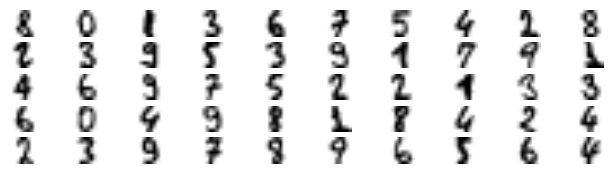

In [54]:
# extra code – this cell generates Figure 8–12

plt.figure(figsize=(8, 2))
for index, X_representative_digit in enumerate(X_representative_digits):
    plt.subplot(k // 10, 10, index + 1)
    plt.imshow(X_representative_digit.reshape(8, 8), cmap="binary",
               interpolation="bilinear")
    plt.axis('off')


plt.show()

In [55]:
y_representative_digits = np.array([
    8, 0, 1, 3, 6, 7, 5, 4, 2, 8,
    2, 3, 9, 5, 3, 9, 1, 7, 9, 1,
    4, 6, 9, 7, 5, 2, 2, 1, 3, 3,
    6, 0, 4, 9, 8, 1, 8, 4, 2, 4,
    2, 3, 9, 7, 8, 9, 6, 5, 6, 4,
])

In [56]:
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_representative_digits, y_representative_digits)
log_reg.score(X_test, y_test)

0.8337531486146096

In [57]:
y_train_propagated = np.empty(len(X_train), dtype=np.int64)
for i in range(k):
    y_train_propagated[kmeans.labels_ == i] = y_representative_digits[i]

In [58]:
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_train, y_train_propagated)

LogisticRegression(max_iter=10000)

In [59]:
log_reg.score(X_test, y_test)

0.8690176322418136

In [60]:
percentile_closest = 50

X_cluster_dist = X_digits_dist[np.arange(len(X_train)), kmeans.labels_]
for i in range(k):
    in_cluster = (kmeans.labels_ == i)
    cluster_dist = X_cluster_dist[in_cluster]
    cutoff_distance = np.percentile(cluster_dist, percentile_closest)
    above_cutoff = (X_cluster_dist > cutoff_distance)
    X_cluster_dist[in_cluster & above_cutoff] = -1

partially_propagated = (X_cluster_dist != -1)
X_train_partially_propagated = X_train[partially_propagated]
y_train_partially_propagated = y_train_propagated[partially_propagated]

In [61]:
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_train_partially_propagated, y_train_partially_propagated)
log_reg.score(X_test, y_test)

0.8841309823677582

In [62]:
(y_train_partially_propagated == y_train[partially_propagated]).mean()

np.float64(0.9887798036465638)

In [63]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)
dbscan = DBSCAN(eps=0.05, min_samples=5)
dbscan.fit(X)

DBSCAN(eps=0.05)

In [64]:
dbscan.labels_[:10]

array([ 0,  2, -1, -1,  1,  0,  0,  0,  2,  5])

In [65]:
len(set(dbscan.labels_) - {-1})

7

In [66]:
dbscan.core_sample_indices_[:10]

array([ 0,  4,  5,  6,  7,  8, 10, 11, 12, 13])

In [67]:
dbscan.components_

array([[-0.02137124,  0.40618608],
       [-0.84192557,  0.53058695],
       [ 0.58930337, -0.32137599],
       ...,
       [ 1.66258462, -0.3079193 ],
       [-0.94355873,  0.3278936 ],
       [ 0.79419406,  0.60777171]], shape=(808, 2))

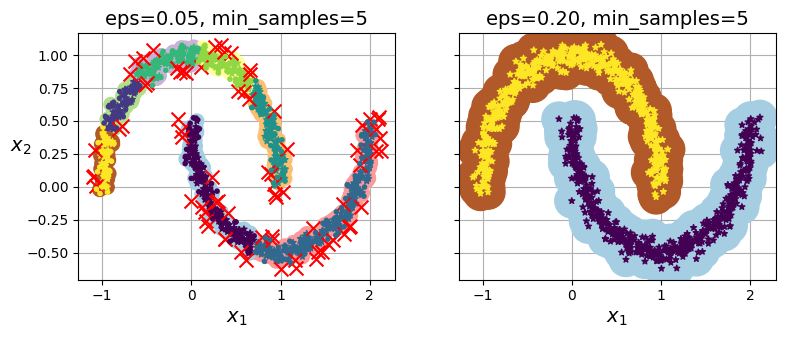

In [68]:
# extra code – this cell generates Figure 8–13

def plot_dbscan(dbscan, X, size, show_xlabels=True, show_ylabels=True):
    core_mask = np.zeros_like(dbscan.labels_, dtype=bool)
    core_mask[dbscan.core_sample_indices_] = True
    anomalies_mask = dbscan.labels_ == -1
    non_core_mask = ~(core_mask | anomalies_mask)

    cores = dbscan.components_
    anomalies = X[anomalies_mask]
    non_cores = X[non_core_mask]

    plt.scatter(cores[:, 0], cores[:, 1],
                c=dbscan.labels_[core_mask], marker='o', s=size, cmap="Paired")
    plt.scatter(cores[:, 0], cores[:, 1], marker='*', s=20,
                c=dbscan.labels_[core_mask])
    plt.scatter(anomalies[:, 0], anomalies[:, 1],
                c="r", marker="x", s=100)
    plt.scatter(non_cores[:, 0], non_cores[:, 1],
                c=dbscan.labels_[non_core_mask], marker=".")
    if show_xlabels:
        plt.xlabel("$x_1$")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)
    plt.title(f"eps={dbscan.eps:.2f}, min_samples={dbscan.min_samples}")
    plt.grid()
    plt.gca().set_axisbelow(True)

dbscan2 = DBSCAN(eps=0.2)
dbscan2.fit(X)

plt.figure(figsize=(9, 3.2))

plt.subplot(121)
plot_dbscan(dbscan, X, size=100)

plt.subplot(122)
plot_dbscan(dbscan2, X, size=600, show_ylabels=False)


plt.show()

In [69]:
dbscan = dbscan2  # extra code – the text says we now use eps=0.2

In [70]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=50)
knn.fit(dbscan.components_, dbscan.labels_[dbscan.core_sample_indices_])

KNeighborsClassifier(n_neighbors=50)

In [71]:
X_new = np.array([[-0.5, 0], [0, 0.5], [1, -0.1], [2, 1]])
knn.predict(X_new)

array([1, 0, 1, 0])

In [72]:
knn.predict_proba(X_new)

array([[0.18, 0.82],
       [1.  , 0.  ],
       [0.12, 0.88],
       [1.  , 0.  ]])

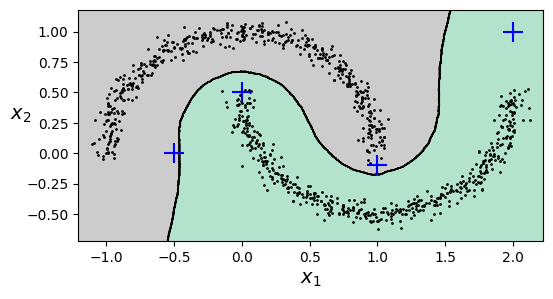

In [73]:
# extra code – this cell generates Figure 8–14

plt.figure(figsize=(6, 3))
plot_decision_boundaries(knn, X, show_centroids=False)
plt.scatter(X_new[:, 0], X_new[:, 1], c="b", marker="+", s=200, zorder=10)

plt.show()

In [74]:
y_dist, y_pred_idx = knn.kneighbors(X_new, n_neighbors=1)
y_pred = dbscan.labels_[dbscan.core_sample_indices_][y_pred_idx]
y_pred[y_dist > 0.2] = -1
y_pred.ravel()

array([-1,  0,  1, -1])

In [75]:
from sklearn.cluster import AgglomerativeClustering

In [76]:
X = np.array([0, 2, 5, 8.5]).reshape(-1, 1)
agg = AgglomerativeClustering(linkage="complete").fit(X)

In [77]:
def learned_parameters(estimator):
    return [attrib for attrib in dir(estimator)
            if attrib.endswith("_") and not attrib.startswith("_")]

In [78]:
learned_parameters(agg)

['children_',
 'labels_',
 'n_clusters_',
 'n_connected_components_',
 'n_features_in_',
 'n_leaves_']

In [79]:
agg.children_

array([[0, 1],
       [2, 3],
       [4, 5]])

In [80]:
from sklearn.cluster import SpectralClustering

In [81]:
sc1 = SpectralClustering(n_clusters=2, gamma=100, random_state=42)
sc1.fit(X)

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


SpectralClustering(gamma=100, n_clusters=2, random_state=42)

In [82]:
sc1.affinity_matrix_.round(2)

array([[1., 0., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 1., 0.],
       [0., 0., 0., 1.]])

In [83]:
sc2 = SpectralClustering(n_clusters=2, gamma=1, random_state=42)
sc2.fit(X)

SpectralClustering(gamma=1, n_clusters=2, random_state=42)

In [84]:
def plot_spectral_clustering(sc, X, size, alpha, show_xlabels=True,
                             show_ylabels=True):
    plt.scatter(X[:, 0], X[:, 1], marker='o', s=size, c='gray', alpha=alpha)
    plt.scatter(X[:, 0], X[:, 1], marker='o', s=30, c='w')
    plt.scatter(X[:, 0], X[:, 1], marker='.', s=10, c=sc.labels_, cmap="Paired")

    if show_xlabels:
        plt.xlabel("$x_1$")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)
    plt.title(f"RBF gamma={sc.gamma}")

In [85]:
from sklearn.datasets import make_moons
from sklearn.cluster import SpectralClustering

# Restore the 2D dataset
X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)

# Train the two models
sc1 = SpectralClustering(
    n_clusters=2, gamma=100, random_state=42
)
sc1.fit(X)

sc2 = SpectralClustering(
    n_clusters=2, gamma=1, random_state=42
)
sc2.fit(X)

# Verify dimensions
print(X.shape)

(1000, 2)


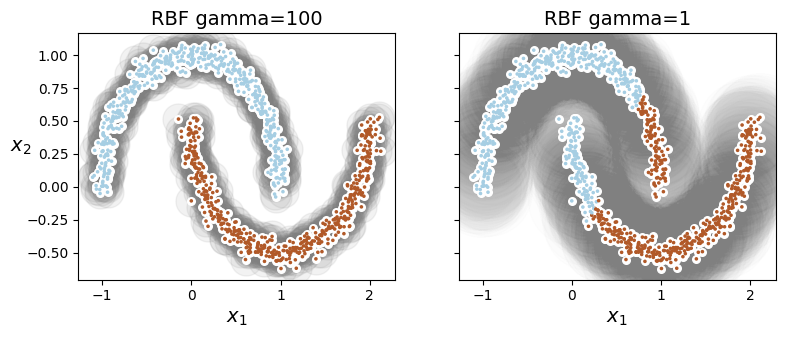

In [86]:
plt.figure(figsize=(9, 3.2))

plt.subplot(121)
plot_spectral_clustering(sc1, X, size=500, alpha=0.1)

plt.subplot(122)
plot_spectral_clustering(sc2, X, size=4000, alpha=0.01, show_ylabels=False)

plt.show()

In [87]:
X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
X = np.r_[X1, X2]
y = np.r_[y1, y2]

In [88]:
from sklearn.mixture import GaussianMixture

In [89]:
gm = GaussianMixture(n_components=3, n_init=10, random_state=42)
gm.fit(X)

GaussianMixture(n_components=3, n_init=10, random_state=42)

In [90]:
gm.weights_

array([0.40005972, 0.20961444, 0.39032584])

In [91]:
gm.means_

array([[-1.40764129,  1.42712848],
       [ 3.39947665,  1.05931088],
       [ 0.05145113,  0.07534576]])

In [92]:
gm.covariances_

array([[[ 0.63478217,  0.72970097],
        [ 0.72970097,  1.16094925]],

       [[ 1.14740131, -0.03271106],
        [-0.03271106,  0.95498333]],

       [[ 0.68825143,  0.79617956],
        [ 0.79617956,  1.21242183]]])

In [93]:
gm.converged_

True

In [94]:
gm.n_iter_

4

In [95]:
gm.predict(X)

array([2, 2, 0, ..., 1, 1, 1], shape=(1250,))

In [96]:
gm.predict_proba(X).round(3)

array([[0.   , 0.023, 0.977],
       [0.001, 0.016, 0.983],
       [1.   , 0.   , 0.   ],
       ...,
       [0.   , 1.   , 0.   ],
       [0.   , 1.   , 0.   ],
       [0.   , 1.   , 0.   ]], shape=(1250, 3))

In [97]:
X_new, y_new = gm.sample(6)
X_new

array([[-2.32491052,  1.04752548],
       [-1.16654983,  1.62795173],
       [ 1.84860618,  2.07374016],
       [ 3.98304484,  1.49869936],
       [ 3.8163406 ,  0.53038367],
       [ 0.38079484, -0.56239369]])

In [98]:
y_new

array([0, 0, 1, 1, 1, 2])

In [99]:
gm.score_samples(X).round(2)

array([-2.61, -3.57, -3.33, ..., -3.51, -4.4 , -3.81], shape=(1250,))

In [100]:
# extra code – bonus material

resolution = 100
grid = np.arange(-10, 10, 1 / resolution)
xx, yy = np.meshgrid(grid, grid)
X_full = np.vstack([xx.ravel(), yy.ravel()]).T

pdf = np.exp(gm.score_samples(X_full))
pdf_probas = pdf * (1 / resolution) ** 2
pdf_probas.sum()

np.float64(0.9999999999225094)

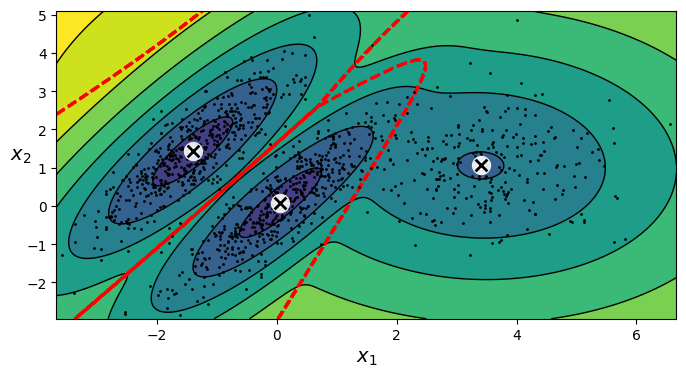

In [101]:
# extra code – this cell generates Figure 8–15

from matplotlib.colors import LogNorm

def plot_gaussian_mixture(clusterer, X, resolution=1000, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = -clusterer.score_samples(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z,
                 norm=LogNorm(vmin=1.0, vmax=30.0),
                 levels=np.logspace(0, 2, 12))
    plt.contour(xx, yy, Z,
                norm=LogNorm(vmin=1.0, vmax=30.0),
                levels=np.logspace(0, 2, 12),
                linewidths=1, colors='k')

    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contour(xx, yy, Z,
                linewidths=2, colors='r', linestyles='dashed')

    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)
    plot_centroids(clusterer.means_, clusterer.weights_)

    plt.xlabel("$x_1$")
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)

plt.figure(figsize=(8, 4))

plot_gaussian_mixture(gm, X)


plt.show()

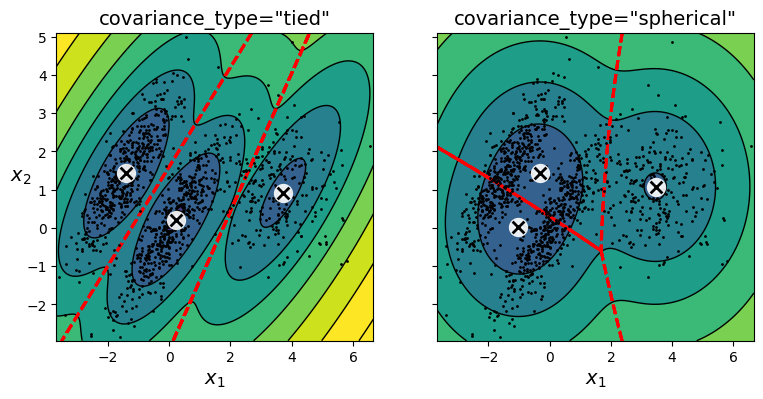

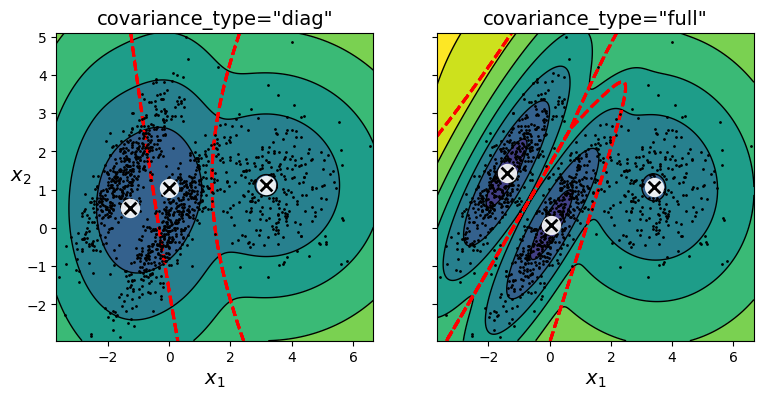

In [102]:
# extra code – this cell generates Figure 8–16

gm_full = GaussianMixture(n_components=3, n_init=10,
                          covariance_type="full", random_state=42)
gm_tied = GaussianMixture(n_components=3, n_init=10,
                          covariance_type="tied", random_state=42)
gm_spherical = GaussianMixture(n_components=3, n_init=10,
                               covariance_type="spherical", random_state=42)
gm_diag = GaussianMixture(n_components=3, n_init=10,
                          covariance_type="diag", random_state=42)
gm_full.fit(X)
gm_tied.fit(X)
gm_spherical.fit(X)
gm_diag.fit(X)

def compare_gaussian_mixtures(gm1, gm2, X):
    plt.figure(figsize=(9, 4))

    plt.subplot(121)
    plot_gaussian_mixture(gm1, X)
    plt.title(f'covariance_type="{gm1.covariance_type}"')

    plt.subplot(122)
    plot_gaussian_mixture(gm2, X, show_ylabels=False)
    plt.title(f'covariance_type="{gm2.covariance_type}"')

compare_gaussian_mixtures(gm_tied, gm_spherical, X)
compare_gaussian_mixtures(gm_diag, gm_full, X)



plt.show()

In [103]:
densities = gm.score_samples(X)
density_threshold = np.percentile(densities, 2)
anomalies = X[densities < density_threshold]

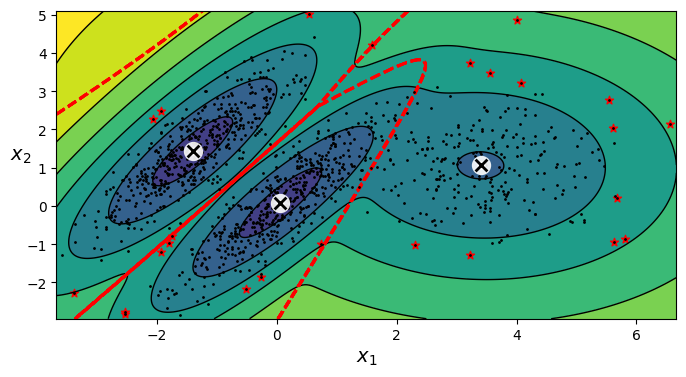

In [104]:
# extra code – this cell generates Figure 8–17

plt.figure(figsize=(8, 4))

plot_gaussian_mixture(gm, X)
plt.scatter(anomalies[:, 0], anomalies[:, 1], color='r', marker='*')
plt.ylim(top=5.1)


plt.show()

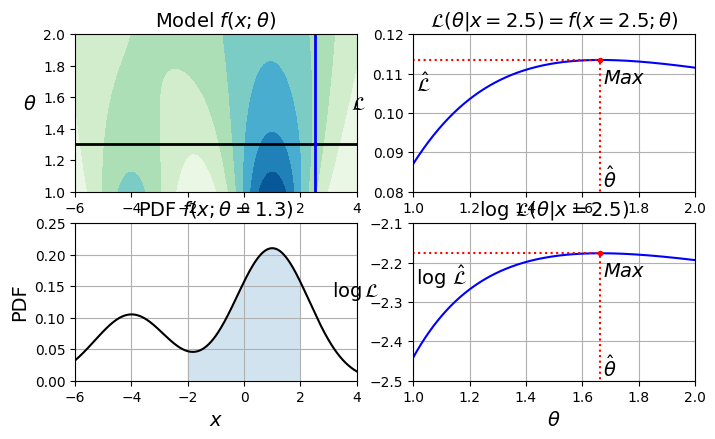

In [105]:
# extra code – this cell generates Figure 8–18

from scipy.stats import norm

x_val = 2.5
std_val = 1.3
x_range = [-6, 4]
x_proba_range = [-2, 2]
stds_range = [1, 2]

xs = np.linspace(x_range[0], x_range[1], 501)
stds = np.linspace(stds_range[0], stds_range[1], 501)
Xs, Stds = np.meshgrid(xs, stds)
Z = 2 * norm.pdf(Xs - 1.0, 0, Stds) + norm.pdf(Xs + 4.0, 0, Stds)
Z = Z / Z.sum(axis=1)[:, np.newaxis] / (xs[1] - xs[0])

x_example_idx = (xs >= x_val).argmax()  # index of the first value >= x_val
max_idx = Z[:, x_example_idx].argmax()
max_val = Z[:, x_example_idx].max()
s_example_idx = (stds >= std_val).argmax()
x_range_min_idx = (xs >= x_proba_range[0]).argmax()
x_range_max_idx = (xs >= x_proba_range[1]).argmax()
log_max_idx = np.log(Z[:, x_example_idx]).argmax()
log_max_val = np.log(Z[:, x_example_idx]).max()

plt.figure(figsize=(8, 4.5))

plt.subplot(2, 2, 1)
plt.contourf(Xs, Stds, Z, cmap="GnBu")
plt.plot([-6, 4], [std_val, std_val], "k-", linewidth=2)
plt.plot([x_val, x_val], [1, 2], "b-", linewidth=2)
plt.ylabel(r"$\theta$", rotation=0, labelpad=10)
plt.title(r"Model $f(x; \theta)$")

plt.subplot(2, 2, 2)
plt.plot(stds, Z[:, x_example_idx], "b-")
plt.plot(stds[max_idx], max_val, "r.")
plt.plot([stds[max_idx], stds[max_idx]], [0, max_val], "r:")
plt.plot([0, stds[max_idx]], [max_val, max_val], "r:")
plt.text(stds[max_idx]+ 0.01, 0.081, r"$\hat{\theta}$")
plt.text(stds[max_idx]+ 0.01, max_val - 0.006, r"$Max$")
plt.text(1.01, max_val - 0.008, r"$\hat{\mathcal{L}}$")
plt.ylabel(r"$\mathcal{L}$", rotation=0, labelpad=10)
plt.title(fr"$\mathcal{{L}}(\theta|x={x_val}) = f(x={x_val}; \theta)$")
plt.grid()
plt.axis([1, 2, 0.08, 0.12])

plt.subplot(2, 2, 3)
plt.plot(xs, Z[s_example_idx], "k-")
plt.fill_between(xs[x_range_min_idx:x_range_max_idx+1],
                 Z[s_example_idx, x_range_min_idx:x_range_max_idx+1], alpha=0.2)
plt.xlabel(r"$x$")
plt.ylabel("PDF")
plt.title(fr"PDF $f(x; \theta={std_val})$")
plt.grid()
plt.axis([-6, 4, 0, 0.25])

plt.subplot(2, 2, 4)
plt.plot(stds, np.log(Z[:, x_example_idx]), "b-")
plt.plot(stds[log_max_idx], log_max_val, "r.")
plt.plot([stds[log_max_idx], stds[log_max_idx]], [-5, log_max_val], "r:")
plt.plot([0, stds[log_max_idx]], [log_max_val, log_max_val], "r:")
plt.text(stds[log_max_idx]+ 0.01, log_max_val - 0.06, r"$Max$")
plt.text(stds[log_max_idx]+ 0.01, -2.49, r"$\hat{\theta}$")
plt.text(1.01, log_max_val - 0.08, r"$\log \, \hat{\mathcal{L}}$")
plt.xlabel(r"$\theta$")
plt.ylabel(r"$\log\mathcal{L}$", rotation=0, labelpad=10)
plt.title(fr"$\log \, \mathcal{{L}}(\theta|x={x_val})$")
plt.grid()
plt.axis([1, 2, -2.5, -2.1])


plt.show()

In [106]:
gm.bic(X)

np.float64(8189.733705221636)

In [107]:
gm.aic(X)

np.float64(8102.508425106598)

In [108]:
# extra code – bonus material
n_clusters = 3
n_dims = 2
n_params_for_weights = n_clusters - 1
n_params_for_means = n_clusters * n_dims
n_params_for_covariance = n_clusters * n_dims * (n_dims + 1) // 2
n_params = n_params_for_weights + n_params_for_means + n_params_for_covariance
max_log_likelihood = gm.score(X) * len(X) # log(L^)
bic = np.log(len(X)) * n_params - 2 * max_log_likelihood
aic = 2 * n_params - 2 * max_log_likelihood
print(f"bic = {bic}")
print(f"aic = {aic}")
print(f"n_params = {n_params}")

bic = 8189.733705221636
aic = 8102.508425106598
n_params = 17


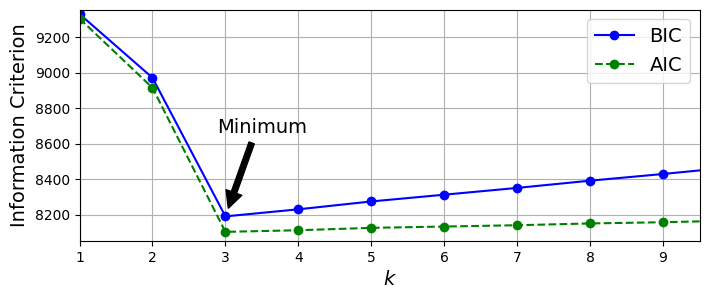

In [109]:
# extra code – this cell generates Figure 8–19

gms_per_k = [GaussianMixture(n_components=k, n_init=10, random_state=42).fit(X)
             for k in range(1, 11)]
bics = [model.bic(X) for model in gms_per_k]
aics = [model.aic(X) for model in gms_per_k]

plt.figure(figsize=(8, 3))
plt.plot(range(1, 11), bics, "bo-", label="BIC")
plt.plot(range(1, 11), aics, "go--", label="AIC")
plt.xlabel("$k$")
plt.ylabel("Information Criterion")
plt.axis([1, 9.5, min(aics) - 50, max(aics) + 50])
plt.annotate("", xy=(3, bics[2]), xytext=(3.4, 8650),
             arrowprops=dict(facecolor='black', shrink=0.1))
plt.text(3.5, 8660, "Minimum", horizontalalignment="center")
plt.legend()
plt.grid()

plt.show()

In [110]:
from sklearn.mixture import BayesianGaussianMixture

bgm = BayesianGaussianMixture(n_components=10, n_init=10, max_iter=500,
                              random_state=42)
bgm.fit(X)
bgm.weights_.round(2)

array([0.4 , 0.21, 0.39, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ])

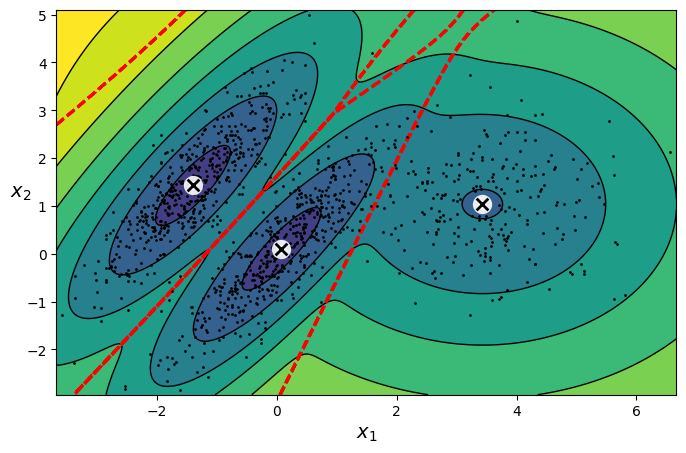

In [111]:
# extra code – this figure is almost identical to Figure 8–16
plt.figure(figsize=(8, 5))
plot_gaussian_mixture(bgm, X)
plt.show()

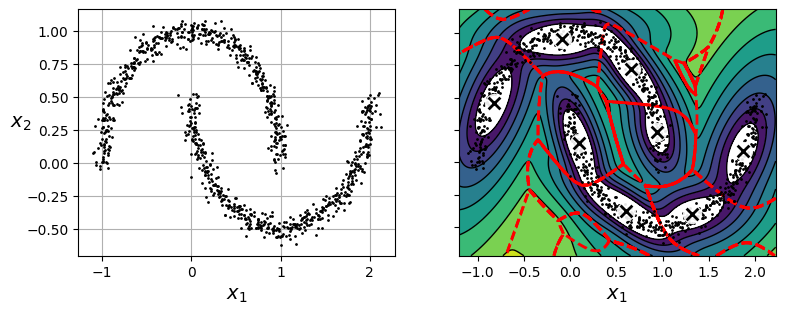

In [112]:
# extra code – this cell generates Figure 8–20

X_moons, y_moons = make_moons(n_samples=1000, noise=0.05, random_state=42)

bgm = BayesianGaussianMixture(n_components=10, n_init=10, max_iter=500, random_state=42)
bgm.fit(X_moons)

plt.figure(figsize=(9, 3.2))

plt.subplot(121)
plot_data(X_moons)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$", rotation=0)
plt.grid()

plt.subplot(122)
plot_gaussian_mixture(bgm, X_moons, show_ylabels=False)


plt.show()

Ex #10

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Training: (240, 4096) | images per person: [6]
Validation: (80, 4096) | images per person: [2]
Test: (80, 4096) | images per person: [2]
Training pixel range: 0.0 to 1.0


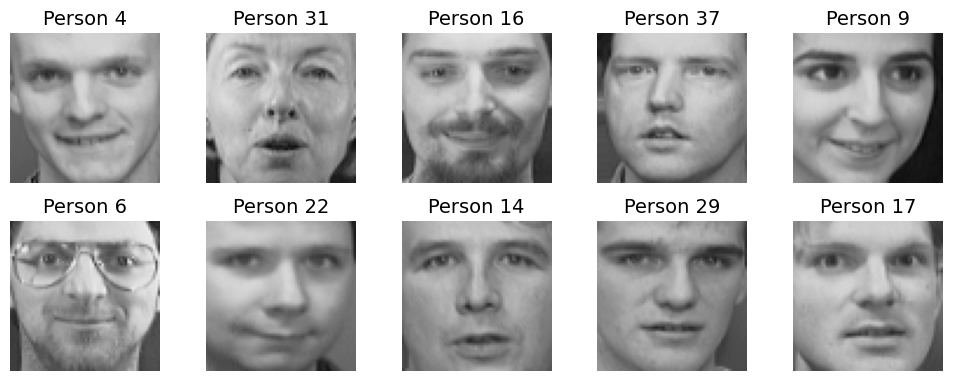

In [113]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

# Each image is 64 × 64 pixels, flattened into 4,096 features.
faces = fetch_olivetti_faces(shuffle=False)

X = faces.data
y = faces.target

# Reserve two images per person for testing: 80 images.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=80,
    stratify=y,
    random_state=42,
)

# Reserve two more per person for validation: 80 images.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=80,
    stratify=y_train_val,
    random_state=42,
)

for name, features, labels in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    _, counts = np.unique(labels, return_counts=True)
    print(
        f"{name}: {features.shape} | "
        f"images per person: {np.unique(counts).tolist()}"
    )

print("Training pixel range:", X_train.min(), "to", X_train.max())

# Preview training images.
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for index, ax in enumerate(axes.flat):
    ax.imshow(
        X_train[index].reshape(64, 64),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.set_title(f"Person {y_train[index]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

k= 5 | silhouette=0.1060 | time=1.1s
k=10 | silhouette=0.0887 | time=1.5s
k=15 | silhouette=0.0947 | time=2.4s
k=20 | silhouette=0.0985 | time=2.5s
k=25 | silhouette=0.1215 | time=7.6s
k=30 | silhouette=0.1248 | time=1.8s
k=35 | silhouette=0.1401 | time=1.8s
k=40 | silhouette=0.1537 | time=1.9s
k=45 | silhouette=0.1502 | time=2.2s
k=50 | silhouette=0.1710 | time=5.7s
k=55 | silhouette=0.1784 | time=2.8s
k=60 | silhouette=0.1916 | time=2.9s
k=65 | silhouette=0.1857 | time=3.1s
k=70 | silhouette=0.1922 | time=6.8s
k=75 | silhouette=0.2047 | time=3.7s
k=80 | silhouette=0.2001 | time=3.8s

Best k by silhouette among tested values: 75


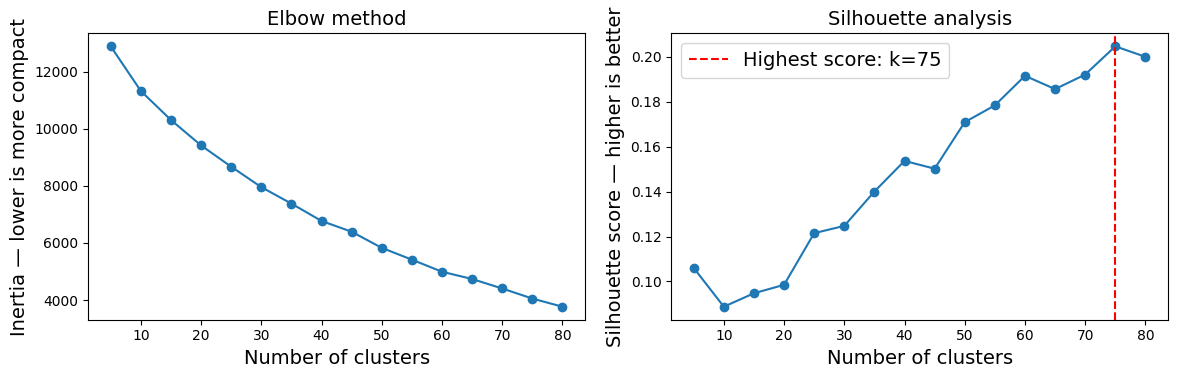

In [114]:
import pandas as pd

from time import perf_counter
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = list(range(5, 81, 5))

# Cache fitted models so we can reuse the selected one.
kmeans_models = {}
cluster_results = []

for k in k_values:
    start = perf_counter()

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42,
    )

    cluster_labels = model.fit_predict(X_train)

    silhouette = silhouette_score(
        X_train,
        cluster_labels,
    )

    kmeans_models[k] = model
    cluster_results.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette,
    })

    print(
        f"k={k:2d} | "
        f"silhouette={silhouette:.4f} | "
        f"time={perf_counter() - start:.1f}s",
        flush=True,
    )

cluster_results = pd.DataFrame(cluster_results)

# Select the highest silhouette score among the tested values.
best_k = int(
    cluster_results.loc[
        cluster_results["Silhouette"].idxmax(), "k"
    ]
)

best_kmeans = kmeans_models[best_k]

print(f"\nBest k by silhouette among tested values: {best_k}")

# Compare the two selection tools visually.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    cluster_results["k"],
    cluster_results["Inertia"],
    marker="o",
)
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia — lower is more compact")

axes[1].plot(
    cluster_results["k"],
    cluster_results["Silhouette"],
    marker="o",
)
axes[1].axvline(
    best_k,
    color="red",
    linestyle="--",
    label=f"Highest score: k={best_k}",
)
axes[1].set_title("Silhouette analysis")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score — higher is better")
axes[1].legend()

plt.tight_layout()
plt.show()

k= 85 | silhouette=0.2044 | time=17.1s
k= 90 | silhouette=0.2066 | time=4.9s
k= 95 | silhouette=0.2039 | time=4.5s
k=100 | silhouette=0.2018 | time=8.3s
k=105 | silhouette=0.2051 | time=5.3s
k=110 | silhouette=0.2037 | time=8.5s
k=115 | silhouette=0.1986 | time=5.4s
k=120 | silhouette=0.1936 | time=9.1s

Top five candidates:
  k     Inertia  Silhouette  Singleton clusters
 90 3342.646729    0.206595                  20
105 2655.268555    0.205058                  31
 75 4052.074951    0.204740                   9
 85 3513.492920    0.204400                  11
 95 3105.178467    0.203918                  26

Best tested k: 90


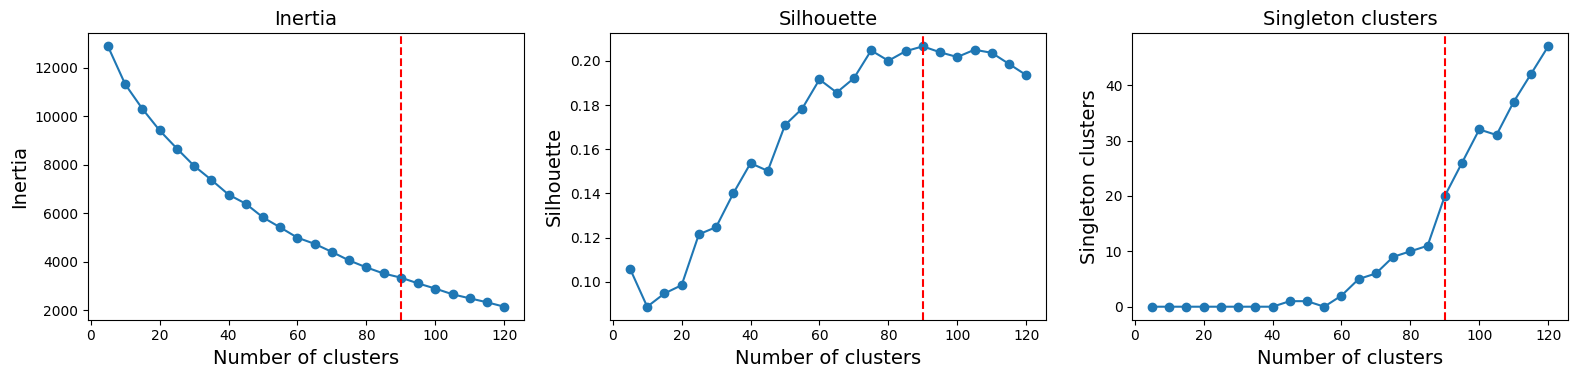

In [115]:
# Extend the existing search.
new_results = []

for k in range(85, 121, 5):
    start = perf_counter()

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42,
    )

    labels = model.fit_predict(X_train)
    score = silhouette_score(X_train, labels)

    kmeans_models[k] = model
    new_results.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette": score,
    })

    print(
        f"k={k:3d} | silhouette={score:.4f} | "
        f"time={perf_counter() - start:.1f}s",
        flush=True,
    )

cluster_results = (
    pd.concat(
        [cluster_results, pd.DataFrame(new_results)],
        ignore_index=True,
    )
    .drop_duplicates("k", keep="last")
    .sort_values("k")
    .reset_index(drop=True)
)

# Count singleton clusters for every fitted model.
cluster_results["Singleton clusters"] = [
    int(np.sum(
        np.bincount(
            kmeans_models[int(k)].labels_,
            minlength=int(k),
        ) == 1
    ))
    for k in cluster_results["k"]
]

best_k = int(
    cluster_results.loc[
        cluster_results["Silhouette"].idxmax(), "k"
    ]
)
best_kmeans = kmeans_models[best_k]

print("\nTop five candidates:")
print(
    cluster_results
    .sort_values("Silhouette", ascending=False)
    .head(5)
    .to_string(index=False)
)
print(f"\nBest tested k: {best_k}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric in zip(
    axes,
    ["Inertia", "Silhouette", "Singleton clusters"],
):
    ax.plot(
        cluster_results["k"],
        cluster_results[metric],
        marker="o",
    )
    ax.axvline(best_k, color="red", linestyle="--")
    ax.set_xlabel("Number of clusters")
    ax.set_ylabel(metric)
    ax.set_title(metric)

plt.tight_layout()
plt.show()

Selected k: 90
Singleton clusters: 20
Largest cluster: 9 images


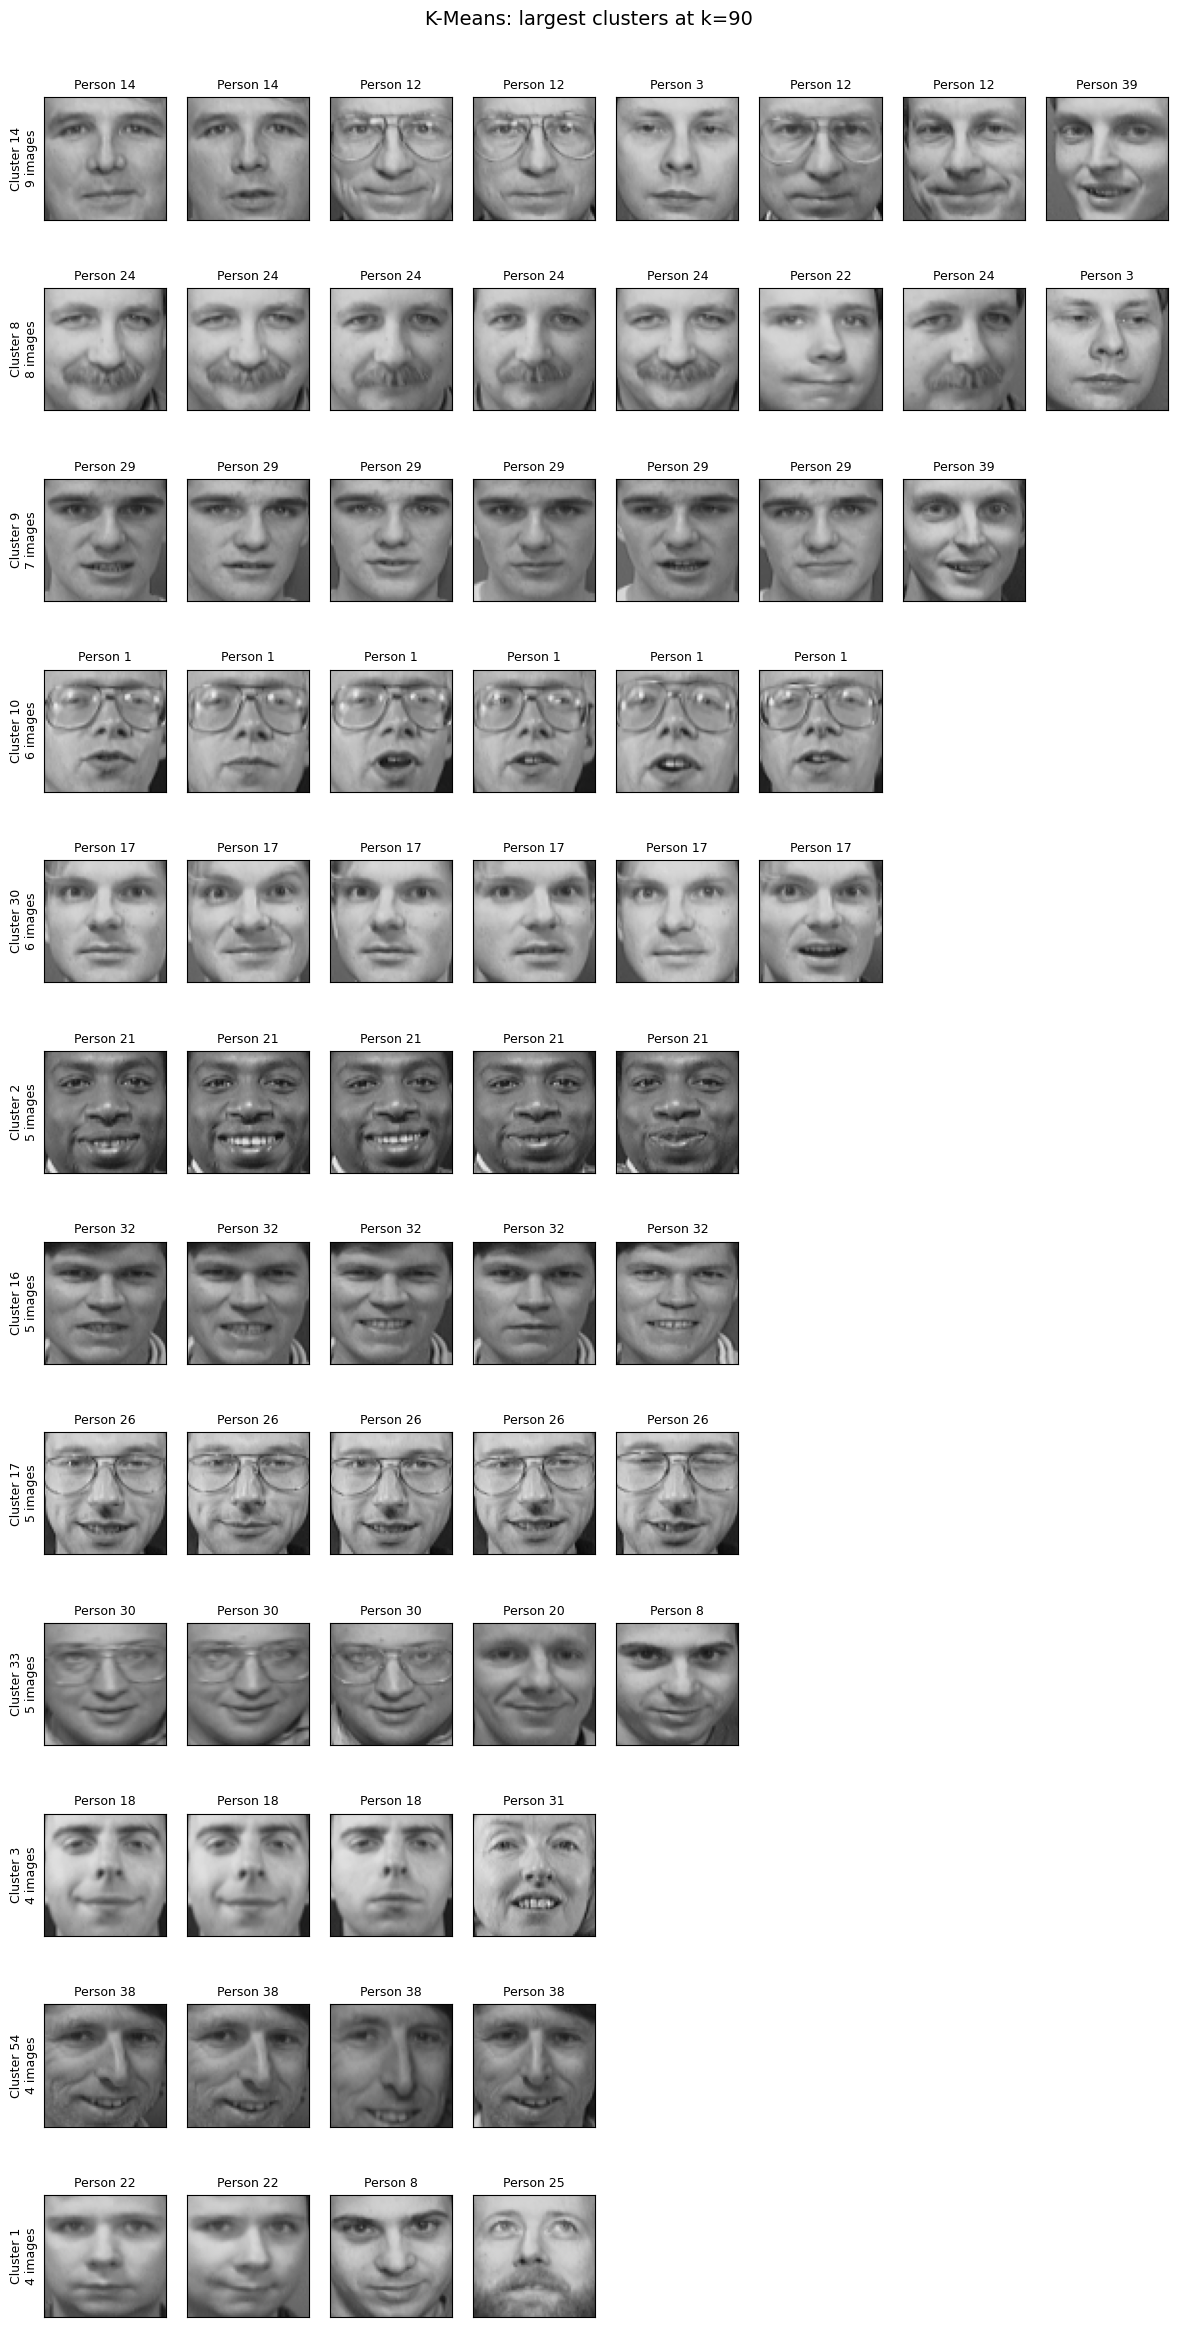

In [116]:
# Reuse the selected fitted model.
best_kmeans = kmeans_models[best_k]
labels = best_kmeans.labels_

cluster_sizes = np.bincount(labels, minlength=best_k)

print(f"Selected k: {best_k}")
print(f"Singleton clusters: {np.sum(cluster_sizes == 1)}")
print(f"Largest cluster: {cluster_sizes.max()} images")

# Show the largest groups rather than mostly singleton clusters.
clusters_to_show = np.argsort(-cluster_sizes)[:12]
max_images = 8

fig, axes = plt.subplots(
    len(clusters_to_show),
    max_images,
    figsize=(12, 2 * len(clusters_to_show)),
    squeeze=False,
)

for row, cluster_id in enumerate(clusters_to_show):
    indices = np.flatnonzero(labels == cluster_id)

    # Display members closest to their assigned centroid first.
    distances = np.linalg.norm(
        X_train[indices] - best_kmeans.cluster_centers_[cluster_id],
        axis=1,
    )
    indices = indices[np.argsort(distances)]

    for col, ax in enumerate(axes[row]):
        ax.set_xticks([])
        ax.set_yticks([])

        if col < len(indices):
            index = indices[col]
            ax.imshow(
                X_train[index].reshape(64, 64),
                cmap="gray",
                vmin=0,
                vmax=1,
            )
            ax.set_title(f"Person {y_train[index]}", fontsize=9)
        else:
            ax.axis("off")

    axes[row, 0].set_ylabel(
        f"Cluster {cluster_id}\n"
        f"{cluster_sizes[cluster_id]} images",
        fontsize=9,
    )

plt.suptitle(
    f"K-Means: largest clusters at k={best_k}",
    fontsize=14,
)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

EX #11

In [118]:
from time import perf_counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

classifier_settings = {
    "n_estimators": 200,
    "n_jobs": -1,
    "random_state": 42,
}

baseline_classifier = RandomForestClassifier(
    **classifier_settings
)

print("Training the original-pixel baseline...", flush=True)
start = perf_counter()

baseline_classifier.fit(X_train, y_train)

baseline_fit_seconds = perf_counter() - start
baseline_val_predictions = baseline_classifier.predict(X_val)

baseline_val_accuracy = accuracy_score(
    y_val,
    baseline_val_predictions,
)

print(f"Input features: {X_train.shape[1]}")
print(f"Validation accuracy: {baseline_val_accuracy:.2%}")
print(
    f"Correct validation predictions: "
    f"{(baseline_val_predictions == y_val).sum()}/{len(y_val)}"
)
print(f"Training time: {baseline_fit_seconds:.2f} seconds")

Training the original-pixel baseline...
Input features: 4096
Validation accuracy: 95.00%
Correct validation predictions: 76/80
Training time: 8.00 seconds


In [119]:
import pandas as pd

distance_classifiers = {}
distance_results = []

for k in sorted(kmeans_models):
    kmeans = kmeans_models[k]

    # One feature per centroid: distance from the image to it.
    X_train_distances = kmeans.transform(X_train)
    X_val_distances = kmeans.transform(X_val)

    classifier = RandomForestClassifier(
        **classifier_settings
    )

    start = perf_counter()
    classifier.fit(X_train_distances, y_train)
    fit_seconds = perf_counter() - start

    predictions = classifier.predict(X_val_distances)
    accuracy = accuracy_score(y_val, predictions)

    distance_classifiers[k] = classifier
    distance_results.append({
        "k": k,
        "Validation accuracy": accuracy,
        "Correct": int((predictions == y_val).sum()),
        "Classifier fit seconds": fit_seconds,
    })

    print(
        f"k={k:3d} | "
        f"validation accuracy={accuracy:.2%} | "
        f"correct={int((predictions == y_val).sum())}/80",
        flush=True,
    )

distance_results = pd.DataFrame(distance_results)

# For tied accuracies, prefer fewer features.
distance_results = distance_results.sort_values(
    ["Validation accuracy", "k"],
    ascending=[False, True],
).reset_index(drop=True)

best_distance_k = int(distance_results.iloc[0]["k"])
best_distance_classifier = distance_classifiers[best_distance_k]

print("\nTop five candidates:")
print(distance_results.head().to_string(
    index=False,
    formatters={"Validation accuracy": "{:.2%}".format},
))

best_distance_val_accuracy = float(
    distance_results.iloc[0]["Validation accuracy"]
)

print(f"\nSelected k: {best_distance_k}")
print(f"Original-pixel baseline: {baseline_val_accuracy:.2%}")
print(f"Best distance-only model: {best_distance_val_accuracy:.2%}")
print(
    "Difference from baseline: "
    f"{100 * (best_distance_val_accuracy - baseline_val_accuracy):+.2f} "
    "percentage points"
)

k=  5 | validation accuracy=56.25% | correct=45/80
k= 10 | validation accuracy=63.75% | correct=51/80
k= 15 | validation accuracy=72.50% | correct=58/80
k= 20 | validation accuracy=71.25% | correct=57/80
k= 25 | validation accuracy=76.25% | correct=61/80
k= 30 | validation accuracy=81.25% | correct=65/80
k= 35 | validation accuracy=76.25% | correct=61/80
k= 40 | validation accuracy=77.50% | correct=62/80
k= 45 | validation accuracy=80.00% | correct=64/80
k= 50 | validation accuracy=80.00% | correct=64/80
k= 55 | validation accuracy=81.25% | correct=65/80
k= 60 | validation accuracy=81.25% | correct=65/80
k= 65 | validation accuracy=82.50% | correct=66/80
k= 70 | validation accuracy=77.50% | correct=62/80
k= 75 | validation accuracy=80.00% | correct=64/80
k= 80 | validation accuracy=82.50% | correct=66/80
k= 85 | validation accuracy=86.25% | correct=69/80
k= 90 | validation accuracy=82.50% | correct=66/80
k= 95 | validation accuracy=83.75% | correct=67/80
k=100 | validation accuracy=85.

In [120]:
# 1. Search using original pixels PLUS centroid distances.
combined_classifiers = {}
combined_rows = []

for k in sorted(kmeans_models):
    kmeans = kmeans_models[k]

    X_train_combined = np.column_stack([
        X_train,
        kmeans.transform(X_train),
    ])
    X_val_combined = np.column_stack([
        X_val,
        kmeans.transform(X_val),
    ])

    classifier = RandomForestClassifier(**classifier_settings)
    classifier.fit(X_train_combined, y_train)

    predictions = classifier.predict(X_val_combined)
    accuracy = accuracy_score(y_val, predictions)

    combined_classifiers[k] = classifier
    combined_rows.append({
        "k": k,
        "Validation accuracy": accuracy,
        "Correct": int(np.sum(predictions == y_val)),
    })

    print(
        f"k={k:3d} | validation accuracy={accuracy:.2%} | "
        f"correct={np.sum(predictions == y_val)}/{len(y_val)}",
        flush=True,
    )

combined_results = (
    pd.DataFrame(combined_rows)
    .sort_values(
        ["Validation accuracy", "k"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

# Break ties by choosing fewer added features.
best_combined_k = int(combined_results.iloc[0]["k"])
best_combined_classifier = combined_classifiers[best_combined_k]
best_combined_val_accuracy = float(
    combined_results.iloc[0]["Validation accuracy"]
)

print("\nTop combined-feature candidates:")
print(combined_results.head().to_string(
    index=False,
    formatters={"Validation accuracy": "{:.2%}".format},
))
print(f"\nSelected combined-feature k: {best_combined_k}")


# 2. Settings are now fixed. Evaluate on the untouched test set.
baseline_test_predictions = baseline_classifier.predict(X_test)

distance_test_predictions = best_distance_classifier.predict(
    kmeans_models[best_distance_k].transform(X_test)
)

X_test_combined = np.column_stack([
    X_test,
    kmeans_models[best_combined_k].transform(X_test),
])
combined_test_predictions = best_combined_classifier.predict(
    X_test_combined
)

test_prediction_sets = {
    "Original pixels": baseline_test_predictions,
    "Distances only": distance_test_predictions,
    "Pixels + distances": combined_test_predictions,
}

final_comparison = pd.DataFrame({
    "Features": [
        X_train.shape[1],
        best_distance_k,
        X_train.shape[1] + best_combined_k,
    ],
    "Selected k": [
        "—",
        str(best_distance_k),
        str(best_combined_k),
    ],
    "Validation accuracy": [
        baseline_val_accuracy,
        best_distance_val_accuracy,
        best_combined_val_accuracy,
    ],
    "Test accuracy": [
        accuracy_score(y_test, predictions)
        for predictions in test_prediction_sets.values()
    ],
    "Correct test predictions": [
        int(np.sum(predictions == y_test))
        for predictions in test_prediction_sets.values()
    ],
}, index=list(test_prediction_sets))

print("\nFINAL COMPARISON")
print(final_comparison.to_string(
    formatters={
        "Validation accuracy": "{:.2%}".format,
        "Test accuracy": "{:.2%}".format,
    }
))

k=  5 | validation accuracy=92.50% | correct=74/80
k= 10 | validation accuracy=92.50% | correct=74/80
k= 15 | validation accuracy=93.75% | correct=75/80
k= 20 | validation accuracy=93.75% | correct=75/80
k= 25 | validation accuracy=92.50% | correct=74/80
k= 30 | validation accuracy=93.75% | correct=75/80
k= 35 | validation accuracy=93.75% | correct=75/80
k= 40 | validation accuracy=95.00% | correct=76/80
k= 45 | validation accuracy=92.50% | correct=74/80
k= 50 | validation accuracy=93.75% | correct=75/80
k= 55 | validation accuracy=92.50% | correct=74/80
k= 60 | validation accuracy=92.50% | correct=74/80
k= 65 | validation accuracy=95.00% | correct=76/80
k= 70 | validation accuracy=92.50% | correct=74/80
k= 75 | validation accuracy=93.75% | correct=75/80
k= 80 | validation accuracy=91.25% | correct=73/80
k= 85 | validation accuracy=93.75% | correct=75/80
k= 90 | validation accuracy=95.00% | correct=76/80
k= 95 | validation accuracy=96.25% | correct=77/80
k=100 | validation accuracy=92.

Using K-Means distances alone reduced test accuracy from 93.75% to 81.25%. Appending centroid distances to the original pixels increased test accuracy to 95.00%, corresponding to one additional correct prediction out of 80. Thus, cluster distances provided a small complementary benefit in this experiment but were an inadequate replacement for the original features.

Ex #12

In [121]:
from time import perf_counter
from sklearn.decomposition import PCA

print("Fitting PCA on training faces...", flush=True)
start = perf_counter()

pca_faces = PCA(
    n_components=0.99,
    svd_solver="full",
)

# Learn the representation from training faces only.
X_train_pca_faces = pca_faces.fit_transform(X_train)

# Apply that same representation to held-out faces.
X_val_pca_faces = pca_faces.transform(X_val)

print(f"Original features: {X_train.shape[1]}")
print(f"PCA components: {pca_faces.n_components_}")
print(
    "Variance retained: "
    f"{pca_faces.explained_variance_ratio_.sum():.4%}"
)
print("Training shape:", X_train_pca_faces.shape)
print("Validation shape:", X_val_pca_faces.shape)
print(f"Elapsed: {perf_counter() - start:.2f} seconds")

Fitting PCA on training faces...
Original features: 4096
PCA components: 176
Variance retained: 99.0088%
Training shape: (240, 176)
Validation shape: (80, 176)
Elapsed: 0.53 seconds


In [122]:
import pandas as pd
from sklearn.mixture import GaussianMixture

component_counts = [1, 2, 3, 5, 8, 10, 15, 20]

gmm_faces_candidates = {}
gmm_faces_rows = []

for n_components in component_counts:
    print(
        f"Fitting GMM with {n_components} components...",
        flush=True,
    )
    start = perf_counter()

    model = GaussianMixture(
        n_components=n_components,
        covariance_type="diag",
        n_init=5,
        reg_covar=1e-4,
        max_iter=300,
        random_state=42,
    )

    model.fit(X_train_pca_faces)

    gmm_faces_candidates[n_components] = model
    gmm_faces_rows.append({
        "Components": n_components,
        "BIC": model.bic(X_train_pca_faces),
        "Validation mean log density": model.score(
            X_val_pca_faces
        ),
        "Converged": model.converged_,
        "Fit seconds": perf_counter() - start,
    })

gmm_faces_results = (
    pd.DataFrame(gmm_faces_rows)
    .sort_values("BIC")
    .reset_index(drop=True)
)

print(gmm_faces_results.to_string(
    index=False,
    formatters={
        "BIC": "{:.1f}".format,
        "Validation mean log density": "{:.2f}".format,
        "Fit seconds": "{:.2f}".format,
    },
))

best_gmm_components = int(
    gmm_faces_results.iloc[0]["Components"]
)
gmm_faces = gmm_faces_candidates[best_gmm_components]

print(f"\nSelected by lowest BIC: {best_gmm_components} components")

Fitting GMM with 1 components...
Fitting GMM with 2 components...
Fitting GMM with 3 components...
Fitting GMM with 5 components...
Fitting GMM with 8 components...
Fitting GMM with 10 components...
Fitting GMM with 15 components...
Fitting GMM with 20 components...
 Components     BIC Validation mean log density  Converged Fit seconds
          1 26696.0                      -30.34       True        0.05
          2 26912.7                      -28.14       True        0.17
          3 28169.1                      -28.14       True        0.18
          5 30937.4                      -27.46       True        0.34
          8 35844.9                      -28.82       True        0.28
         10 38932.8                      -27.41       True        0.22
         15 45956.2                      -30.01       True        1.24
         20 52056.6                      -29.16       True        0.92

Selected by lowest BIC: 1 components


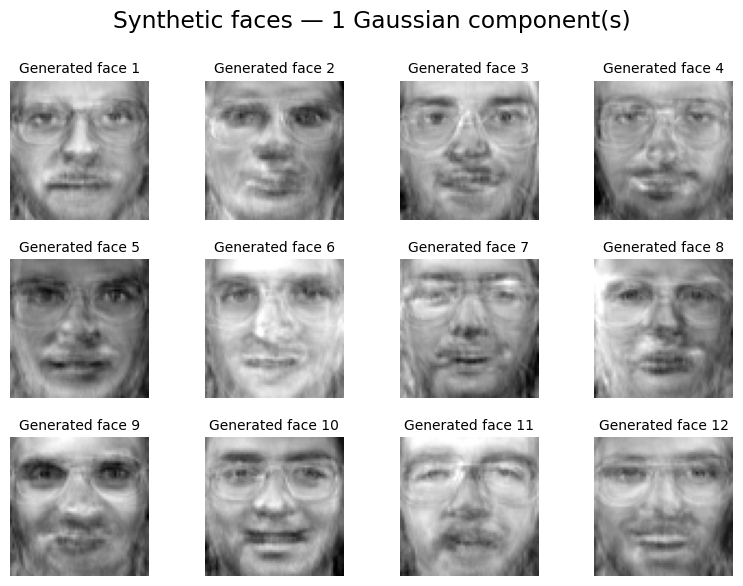

In [123]:
import numpy as np
import matplotlib.pyplot as plt

# Sample 12 synthetic observations in PCA space.
generated_pca_faces, generated_component_ids = gmm_faces.sample(12)

# Reconstruct them in the original 4,096-pixel space.
generated_faces_raw = pca_faces.inverse_transform(
    generated_pca_faces
)

# Gaussian samples can reconstruct outside the valid pixel range.
# Clip for display only.
generated_faces_display = np.clip(generated_faces_raw, 0, 1)

fig, axes = plt.subplots(3, 4, figsize=(8, 6))

for index, ax in enumerate(axes.flat):
    ax.imshow(
        generated_faces_display[index].reshape(64, 64),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.set_title(f"Generated face {index + 1}", fontsize=10)
    ax.axis("off")

plt.suptitle(
    f"Synthetic faces — {gmm_faces.n_components} Gaussian component(s)"
)
plt.tight_layout()
plt.show()

                     Mean log density Mean change from original Fraction lower than original
Version                                                                                     
Original                       -30.34                     +0.00                          NaN
Rotated 90°                   -149.76                   -119.42                       100.0%
Flipped horizontally           -39.72                     -9.38                        80.0%
Darkened                       -25.27                     +5.07                        46.2%


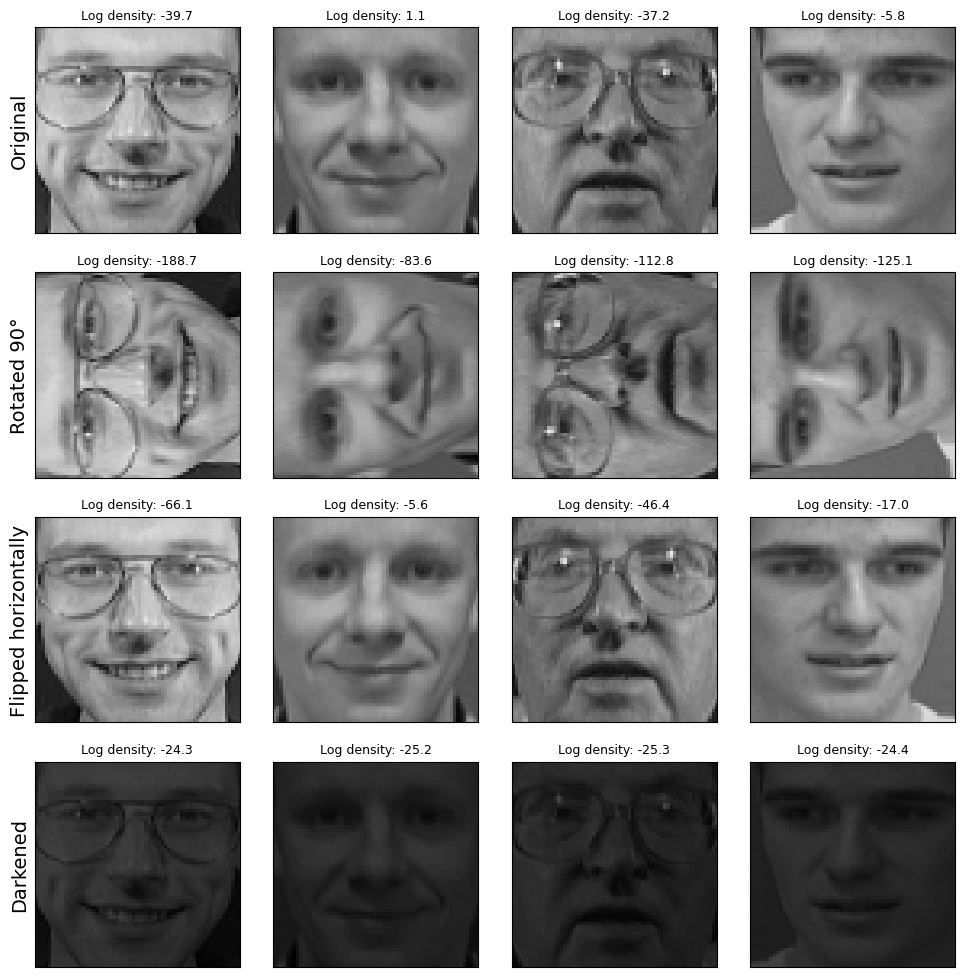

In [124]:
# Use all 80 held-out validation faces.
normal_face_images = X_val.reshape(-1, 64, 64)

modified_face_sets = {
    "Original": normal_face_images.copy(),
    "Rotated 90°": np.rot90(
        normal_face_images, k=1, axes=(1, 2)
    ).copy(),
    "Flipped horizontally": normal_face_images[:, :, ::-1].copy(),
    "Darkened": normal_face_images * 0.3,
}

# Score every version using the SAME fitted PCA and GMM.
face_log_scores = {}

for name, images in modified_face_sets.items():
    flat_images = images.reshape(len(images), -1)
    components = pca_faces.transform(flat_images)
    face_log_scores[name] = gmm_faces.score_samples(components)

original_scores = face_log_scores["Original"]

# Compare each modification against its matching original image.
score_rows = []

for name, scores in face_log_scores.items():
    score_rows.append({
        "Version": name,
        "Mean log density": scores.mean(),
        "Mean change from original": (
            scores - original_scores
        ).mean(),
        "Fraction lower than original": (
            np.nan if name == "Original"
            else np.mean(scores < original_scores)
        ),
    })

anomaly_comparison = pd.DataFrame(score_rows).set_index("Version")

print(anomaly_comparison.to_string(
    formatters={
        "Mean log density": "{:.2f}".format,
        "Mean change from original": "{:+.2f}".format,
        "Fraction lower than original": (
            lambda value: "—" if np.isnan(value) else f"{value:.1%}"
        ),
    }
))

# Show four matched examples from each version.
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for row, (name, images) in enumerate(modified_face_sets.items()):
    for col in range(4):
        ax = axes[row, col]
        ax.imshow(images[col], cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"Log density: {face_log_scores[name][col]:.1f}",
            fontsize=9,
        )
        ax.set_xticks([])
        ax.set_yticks([])

        if col == 0:
            ax.set_ylabel(name)

plt.tight_layout()
plt.show()

PCA reduced the faces to 176 components while retaining approximately 99% of training variance. BIC selected a one-component Gaussian model. Sampling from it produced recognizable but imperfect synthetic faces. Rotating validation faces reduced log density for every image, while horizontal flipping reduced it for 80%. Darkening did not consistently reduce density and increased the average score. Thus, the model captured some unusual changes but was not a reliable detector of every modification.

EX #13

                     Mean reconstruction MSE Median reconstruction MSE Fraction higher than original
Version                                                                                             
Original                            0.002253                  0.001981                           NaN
Rotated 90°                         0.008157                  0.007778                        100.0%
Flipped horizontally                0.003147                  0.003004                         93.8%
Darkened                            0.001096                  0.001075                          6.2%


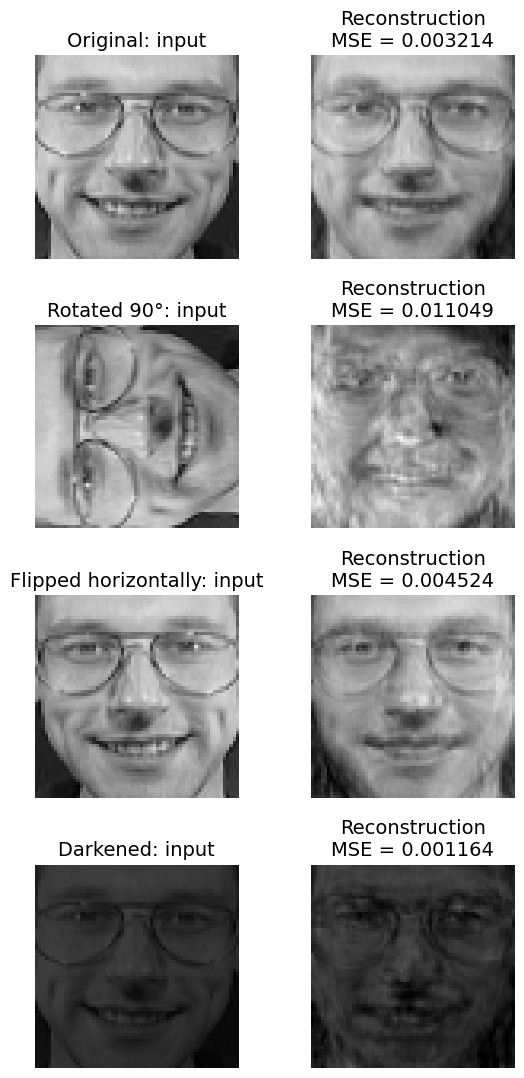

In [125]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

face_reconstructions = {}
face_reconstruction_errors = {}

for name, images in modified_face_sets.items():
    flat_images = images.reshape(len(images), -1)

    # Compress and reconstruct using the same training-fitted PCA.
    components = pca_faces.transform(flat_images)
    reconstructed = pca_faces.inverse_transform(components)

    # One mean squared error per image.
    # Use raw reconstructions: clipping would change the measured error.
    errors = np.mean(
        (flat_images - reconstructed) ** 2,
        axis=1,
    )

    face_reconstructions[name] = reconstructed.reshape(-1, 64, 64)
    face_reconstruction_errors[name] = errors


# Compare each modified image with its matching original.
original_errors = face_reconstruction_errors["Original"]

error_rows = []

for name, errors in face_reconstruction_errors.items():
    error_rows.append({
        "Version": name,
        "Mean reconstruction MSE": errors.mean(),
        "Median reconstruction MSE": np.median(errors),
        "Fraction higher than original": (
            np.nan if name == "Original"
            else np.mean(errors > original_errors)
        ),
    })

reconstruction_comparison = pd.DataFrame(
    error_rows
).set_index("Version")

print(reconstruction_comparison.to_string(
    formatters={
        "Mean reconstruction MSE": "{:.6f}".format,
        "Median reconstruction MSE": "{:.6f}".format,
        "Fraction higher than original": (
            lambda value: "—" if np.isnan(value)
            else f"{value:.1%}"
        ),
    },
))


# Show one matching face under every modification.
# Each row: input image and its PCA reconstruction.
example_index = 0

fig, axes = plt.subplots(
    len(modified_face_sets), 2,
    figsize=(6, 11),
)

for row, (name, images) in enumerate(modified_face_sets.items()):
    axes[row, 0].imshow(
        images[example_index],
        cmap="gray", vmin=0, vmax=1,
    )
    axes[row, 0].set_title(f"{name}: input")

    axes[row, 1].imshow(
        np.clip(
            face_reconstructions[name][example_index], 0, 1
        ),
        cmap="gray", vmin=0, vmax=1,
    )
    axes[row, 1].set_title(
        "Reconstruction\n"
        f"MSE = "
        f"{face_reconstruction_errors[name][example_index]:.6f}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

PCA reconstruction error increased for every rotated validation image and for 93.8% of horizontally flipped images. However, darkened images usually had lower reconstruction error than their originals. Reconstruction error therefore captured some structural changes but was not a reliable indicator of every unusual modification. A low error indicates that an image lies near the learned PCA representation, rather than proving that it is normal.